# Exploratory Data Analysis & Data Quality Audit (Part 2)

This notebook performs the dataset audit and exploratory analysis for the UCI
*Predict Students' Dropout and Academic Success* dataset (`data/data.csv`, 4,424 students,
36 features). It establishes the empirical baselines behind our chronological leakage
design (T0 / T1 / T2) and subgroup fairness audit:

1. Schema, missing values, duplicates, and target class balance (`multiclass` vs `binary`)
2. Observed dropout rates across `Gender`, `Scholarship holder`, `Age at enrollment`, `Course`, and in-year financial flags
3. Structural edge cases:
   - The 180 students with `enrolled == 0` (all in `Course == 171`) vs 538 students who enrolled and passed 0 units
   - Scale mismatch between entry grades (`0–200`) and university grades (`0–20`)
   - Macroeconomic indicators (`GDP`, `Unemployment rate`, `Inflation rate`) forming only 10 unique intake-cohort profiles

In [8]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():          # started from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.features import add_domain_features, get_xy, load_data

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "text.color": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
})

df = load_data()
df_eng = add_domain_features(df)
print(f"Loaded data.csv: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()} | Duplicate rows: {df.duplicated().sum()}")

Loaded data.csv: 4,424 rows x 37 columns
Missing values: 0 | Duplicate rows: 0


## 1. Target Distribution & Modeling Cohorts

- **3-class (`multiclass`)**: all 4,424 students (`Dropout`, `Enrolled`, `Graduate`).
- **2-class (`binary`)**: 3,630 resolved students (`Dropout` vs `Graduate`); the 794 `Enrolled` students are held out for risk-distribution inspection.

In [9]:
counts = df[C.TARGET].value_counts().reindex(["Dropout", "Enrolled", "Graduate"])
pct = counts / len(df) * 100
summary_target = pd.DataFrame({"count": counts, "percent": pct.round(2)})
display(summary_target)

binary_df = df[df[C.TARGET] != "Enrolled"]
print(f"Binary cohort: n = {len(binary_df):,} "
      f"(Dropout = {(binary_df[C.TARGET] == 'Dropout').mean():.1%}, "
      f"Graduate = {(binary_df[C.TARGET] == 'Graduate').mean():.1%})")

,count,percent
Target,,
Dropout,1421,32.12
Enrolled,794,17.95
Graduate,2209,49.93


Binary cohort: n = 3,630 (Dropout = 39.1%, Graduate = 60.9%)


## 2. Observed Dropout Rates by Demographic, Socioeconomic & Financial Subgroups

These observed base rates explain why enrollment-only models (T0) rely heavily on
`Gender`, `Scholarship holder`, `Age at enrollment`, and `Course`, and why Subgroup
Fairness Auditing (RQ2) is critical.

In [10]:
def subgroup_table(data, col, label_map=None):
    g = data.copy()
    if label_map is not None:
        g[col] = g[col].map(label_map)
    t = g.groupby(col)[C.TARGET].agg(
        n="size",
        dropout_n=lambda s: (s == "Dropout").sum(),
        dropout_rate=lambda s: (s == "Dropout").mean(),
        enrolled_rate=lambda s: (s == "Enrolled").mean(),
        graduate_rate=lambda s: (s == "Graduate").mean(),
    )
    return t.round(4)

print("--- Gender ---")
display(subgroup_table(df, "Gender", {0: "Female", 1: "Male"}))

print("--- Scholarship holder ---")
display(subgroup_table(df, "Scholarship holder", {0: "Non-Scholarship", 1: "Scholarship"}))

print("--- Tuition fees up to date (available at T1) ---")
display(subgroup_table(df, "Tuition fees up to date", {0: "Behind on fees", 1: "Up to date"}))

print("--- Debtor (available at T1) ---")
display(subgroup_table(df, "Debtor", {0: "No", 1: "Yes"}))

df["Age group"] = pd.cut(df["Age at enrollment"], bins=[0, 20, 24, 29, 100],
                         labels=["<=20", "21-24", "25-29", "30+"])
print("--- Age at enrollment ---")
display(subgroup_table(df, "Age group"))

--- Gender ---


,n,dropout_n,dropout_rate,enrolled_rate,graduate_rate
Gender,,,,,
Female,2868,720,0.2510,0.1698,0.5791
Male,1556,701,0.4505,0.1973,0.3522


--- Scholarship holder ---


,n,dropout_n,dropout_rate,enrolled_rate,graduate_rate
Scholarship holder,,,,,
Non-Scholarship,3325,1287,0.3871,0.1997,0.4132
Scholarship,1099,134,0.1219,0.1183,0.7598


--- Tuition fees up to date (available at T1) ---


,n,dropout_n,dropout_rate,enrolled_rate,graduate_rate
Tuition fees up to date,,,,,
Behind on fees,528,457,0.8655,0.0795,0.0549
Up to date,3896,964,0.2474,0.1930,0.5595


--- Debtor (available at T1) ---


,n,dropout_n,dropout_rate,enrolled_rate,graduate_rate
Debtor,,,,,
No,3921,1109,0.2828,0.1795,0.5376
Yes,503,312,0.6203,0.1789,0.2008


--- Age at enrollment ---


C:\Users\sonan\AppData\Local\Temp\ipykernel_48320\857119974.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = g.groupby(col)[C.TARGET].agg(


,n,dropout_n,dropout_rate,enrolled_rate,graduate_rate
Age group,,,,,
<=20,2551,542,0.2125,0.1846,0.6029
21-24,735,248,0.3374,0.2190,0.4435
25-29,427,246,0.5761,0.1686,0.2553
30+,711,385,0.5415,0.1266,0.3319


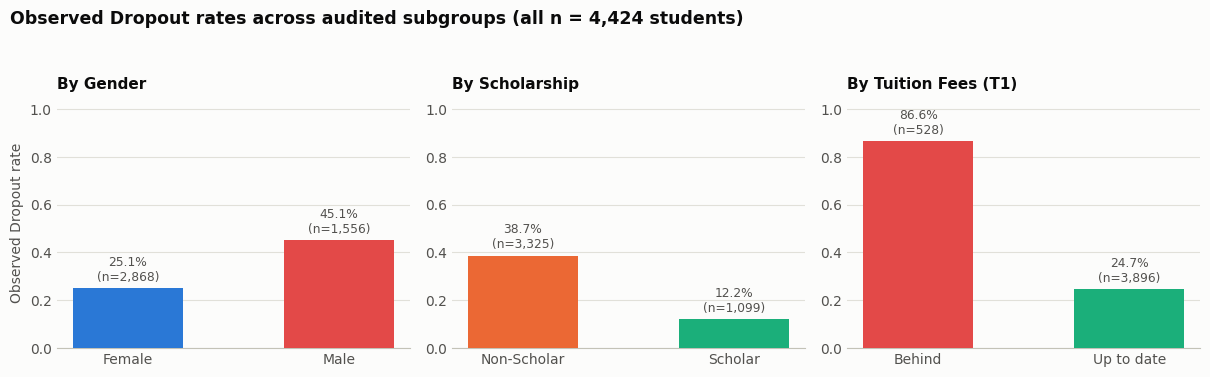

In [11]:
# Plot observed dropout rates across key subgroups
fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.8))
panels = [
    ("Gender", {0: "Female", 1: "Male"}, [BLUE, RED], "By Gender"),
    ("Scholarship holder", {0: "Non-Scholar", 1: "Scholar"}, [ORANGE, AQUA], "By Scholarship"),
    ("Tuition fees up to date", {0: "Behind", 1: "Up to date"}, [RED, AQUA], "By Tuition Fees (T1)"),
]
for ax, (col, lmap, cols, title) in zip(axes, panels):
    t = subgroup_table(df, col, lmap)
    bars = ax.bar(t.index, t["dropout_rate"], color=cols, width=0.52, zorder=3)
    for b, n_val in zip(bars, t["n"]):
        h = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, h + 0.02,
                f"{h:.1%}\n(n={n_val:,})", ha="center", va="bottom", fontsize=8.8, color=INK2)
    ax.set_ylim(0, 1.05)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel("Observed Dropout rate" if ax is axes[0] else "")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)

fig.suptitle("Observed Dropout rates across audited subgroups (all n = 4,424 students)",
             x=0.012, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
C.FIGURES_DIR.mkdir(exist_ok=True)
fig.savefig(C.FIGURES_DIR / "eda_subgroups.png", dpi=180)
plt.show()

## 3. Domain Ratio Edge Cases & Structural Data Audit

1. **Zero-enrolled vs Zero-approved ambiguity:** In `src/features.py`, `Approval ratio` is set to `0.0` when `enrolled == 0`. Below we verify that the 180 zero-enrolled students are the **exact same students in both semesters** and **100% belong to `Course == 171`** (with a 42.8% dropout rate), whereas students who enrolled and passed 0 units have a 91.6% dropout rate in Sem 1 (94.2% in Sem 2).
2. **Scale mismatch:** Entry scores (`Previous qualification (grade)`, `Admission grade`) use the 0–200 Portuguese secondary scale, while semester grades use the 0–20 university scale.
3. **Macroeconomic intake cohorts:** `Unemployment rate`, `Inflation rate`, and `GDP` take only 10 unique combinations across all 4,424 students (one per enrollment cohort).

In [12]:
for sem in ("1st", "2nd"):
    enr = df[f"Curricular units {sem} sem (enrolled)"]
    app = df[f"Curricular units {sem} sem (approved)"]
    no_enr = df[enr == 0]
    fail_all = df[(enr > 0) & (app == 0)]
    print(f"=== {sem} Semester ===")
    print(f"  enrolled == 0:               n={len(no_enr):3d} | targets={no_enr[C.TARGET].value_counts().to_dict()} "
          f"| courses={no_enr['Course'].value_counts().to_dict()}")
    print(f"  enrolled > 0 & approved == 0: n={len(fail_all):3d} | targets={fail_all[C.TARGET].value_counts().to_dict()}")

same_180 = (
    (df["Curricular units 1st sem (enrolled)"] == 0)
    == (df["Curricular units 2nd sem (enrolled)"] == 0)
).all()
print("\nSame 180 students have enrolled == 0 in both semesters:", same_180)

# Scale audit & macro cohorts
scale_cols = [
    "Previous qualification (grade)", "Admission grade",
    "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)",
]
display(df[scale_cols].describe().T[["min", "25%", "50%", "75%", "max"]].round(2))

macro_cols = ["Unemployment rate", "Inflation rate", "GDP"]
macro_cohorts = df.groupby(macro_cols)[C.TARGET].agg(
    n="size", dropout_rate=lambda s: (s == "Dropout").mean()
).reset_index()
print(f"Unique macroeconomic cohort combinations: {len(macro_cohorts)}")
display(macro_cohorts.round(3))

=== 1st Semester ===
  enrolled == 0:               n=180 | targets={'Dropout': 77, 'Graduate': 75, 'Enrolled': 28} | courses={171: 180}
  enrolled > 0 & approved == 0: n=538 | targets={'Dropout': 493, 'Enrolled': 43, 'Graduate': 2}
=== 2nd Semester ===
  enrolled == 0:               n=180 | targets={'Dropout': 77, 'Graduate': 75, 'Enrolled': 28} | courses={171: 180}
  enrolled > 0 & approved == 0: n=690 | targets={'Dropout': 650, 'Enrolled': 40}

Same 180 students have enrolled == 0 in both semesters: True


,min,25%,50%,75%,max
Previous qualification (grade),95.0,125.00,133.10,140.00,190.00
Admission grade,95.0,117.90,126.10,134.80,190.00
Curricular units 1st sem (grade),0.0,11.00,12.29,13.40,18.88
Curricular units 2nd sem (grade),0.0,10.75,12.20,13.33,18.57


Unique macroeconomic cohort combinations: 10


,Unemployment rate,Inflation rate,GDP,n,dropout_rate
0,7.6,2.6,0.32,571,0.354
1,8.9,1.4,3.51,368,0.277
2,9.4,-0.8,-3.12,533,0.326
3,10.8,1.4,1.74,525,0.347
4,11.1,0.6,2.02,414,0.283
5,12.4,0.5,1.79,445,0.240
6,12.7,3.7,-1.70,419,0.337
7,13.9,-0.3,0.79,390,0.303
8,15.5,2.8,-4.06,397,0.350
9,16.2,0.3,-0.92,362,0.384


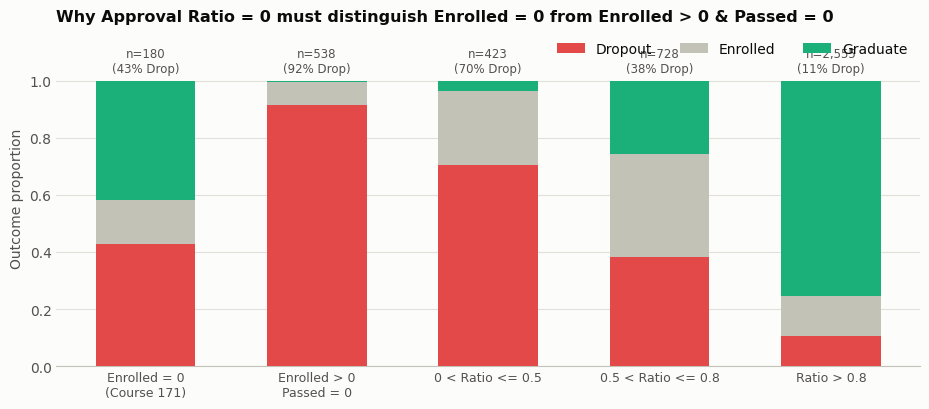

In [13]:
# Plot: Approval ratio = 0 conflates two very different student populations
enr1 = df["Curricular units 1st sem (enrolled)"]
app1 = df["Curricular units 1st sem (approved)"]
df["sem1_bucket"] = np.select(
    [enr1 == 0, (enr1 > 0) & (app1 == 0),
     df_eng["Approval ratio 1st sem"] <= 0.5,
     df_eng["Approval ratio 1st sem"] <= 0.8],
    ["Enrolled = 0\n(Course 171)", "Enrolled > 0\nPassed = 0", "0 < Ratio <= 0.5", "0.5 < Ratio <= 0.8"],
    default="Ratio > 0.8",
)
order = ["Enrolled = 0\n(Course 171)", "Enrolled > 0\nPassed = 0",
         "0 < Ratio <= 0.5", "0.5 < Ratio <= 0.8", "Ratio > 0.8"]
bt = df.groupby("sem1_bucket")[C.TARGET].agg(
    n="size",
    Dropout=lambda s: (s == "Dropout").mean(),
    Enrolled=lambda s: (s == "Enrolled").mean(),
    Graduate=lambda s: (s == "Graduate").mean(),
).reindex(order)

fig, ax = plt.subplots(figsize=(9.4, 4.2))
x = np.arange(len(bt))
ax.bar(x, bt["Dropout"], label="Dropout", color=RED, width=0.58, zorder=3)
ax.bar(x, bt["Enrolled"], bottom=bt["Dropout"], label="Enrolled", color="#c3c2b7", width=0.58, zorder=3)
ax.bar(x, bt["Graduate"], bottom=bt["Dropout"] + bt["Enrolled"], label="Graduate", color=AQUA, width=0.58, zorder=3)
for i, (n_val, d_rate) in enumerate(zip(bt["n"], bt["Dropout"])):
    ax.text(i, 1.02, f"n={n_val:,}\n({d_rate:.0%} Drop)", ha="center", va="bottom", fontsize=8.5, color=INK2)

ax.set_xticks(x, bt.index, fontsize=9)
ax.set_ylim(0, 1.18)
ax.set_ylabel("Outcome proportion")
ax.set_title("Why Approval Ratio = 0 must distinguish Enrolled = 0 from Enrolled > 0 & Passed = 0",
             loc="left", fontsize=11.5, fontweight="bold")
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(C.FIGURES_DIR / "eda_edge_cases.png", dpi=180)
plt.show()

## 4. Chronological Stage & Leakage Guard Verification

Confirm exact feature counts at each stage (`T0 = 22`, `T1 = 31`, `T2 = 39`) and verify
that `src.features.get_xy` blocks all future-semester columns from earlier stages.

In [14]:
for task in ("multiclass", "binary"):
    print(f"=== Task: {task} ===")
    for stage in ("T0", "T1", "T2"):
        X, y, idx, classes = get_xy(df, stage, task)
        print(f"  {stage}: X={X.shape}, classes={classes}, target_dist={np.bincount(y).tolist()}")

=== Task: multiclass ===
  T0: X=(4424, 22), classes=['Dropout', 'Enrolled', 'Graduate'], target_dist=[1421, 794, 2209]
  T1: X=(4424, 31), classes=['Dropout', 'Enrolled', 'Graduate'], target_dist=[1421, 794, 2209]
  T2: X=(4424, 39), classes=['Dropout', 'Enrolled', 'Graduate'], target_dist=[1421, 794, 2209]
=== Task: binary ===
  T0: X=(3630, 22), classes=['Graduate', 'Dropout'], target_dist=[2209, 1421]
  T1: X=(3630, 31), classes=['Graduate', 'Dropout'], target_dist=[2209, 1421]
  T2: X=(3630, 39), classes=['Graduate', 'Dropout'], target_dist=[2209, 1421]
